In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
%matplotlib inline

In [3]:
df = pd.read_csv("bean-there-coffee.csv")

In [5]:
df = pd.read_csv("bean-there-coffee.csv")
df.head()

,transaction_id,timestamp,store,product,category,size,unit_price,quantity,payment_method,discount_code
0,T506385,2025-05-20 17:15:06,Airport,Cappuccino,Coffee,Large,6.48,3,Cash,NaN
1,T504245,2025-07-02 11:19:43,Airport,Cappuccino,Coffee,Medium,5.88,2,Card,NaN
2,T501851,2025-03-26 11:30:15,Campus,Bottled Water,Other,NaN,2.00,2,Cash,NaN
3,T504043,2025-06-01 08:28:06,Airport,Drip Coffee,Coffee,Large,4.32,2,Card,NaN
4,T502525,2025-04-03 20:54:00,Campus,Latte,Coffee,Small,4.60,4,Mobile,NaN


In [6]:
df.tail()

,transaction_id,timestamp,store,product,category,size,unit_price,quantity,payment_method,discount_code
8045,T503257,2025-03-25 06:00:00,Campus,Bagel,Bakery,NaN,2.8,2,Mobile,NaN
8046,T505986,2025-06-15 08:49:08,Downtown,Latte,Coffee,Small,4.6,2,Card,NaN
8047,T502020,2025-07-12 11:15:22,Campus,Croissant,Bakery,NaN,3.4,4,Card,HAPPYHOUR
8048,T502581,2025-04-15 11:37:50,campus,Cappuccino,Coffee,Small,4.4,2,Mobile,NaN
8049,T506459,2025-06-28 15:21:27,Airport,Espresso,Coffee,Large,4.8,3,Card,NaN


## Data Understanding and Cleaning Summary
* I removed the duplicates because they repeat the same transaction ID and would double-count sales. I removed the negative quantities because they look like returns, which would subtract from sales counts and confuse a chart of what customers buy. I removed the $0 prices because they are spread across every product, so they look like errors that would distort the price histogram. The final cleaned table has 7,890 rows. I also created revenue (unit price × quantity), plus hour and month from the timestamp. Note that unit_price does not change with a discount code, so revenue is measured before discounts. One more thing: 12 transactions are stamped around 3 AM, while all others fall between 6 AM and 8 PM. These are probably timestamp errors, so I left them out of the hourly chart.

In [11]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()

Rows: 8050, Columns: 10


,transaction_id,timestamp,store,product,category,size,unit_price,quantity,payment_method,discount_code
0,T506385,2025-05-20 17:15:06,Airport,Cappuccino,Coffee,Large,6.48,3,Cash,NaN
1,T504245,2025-07-02 11:19:43,Airport,Cappuccino,Coffee,Medium,5.88,2,Card,NaN
2,T501851,2025-03-26 11:30:15,Campus,Bottled Water,Other,NaN,2.00,2,Cash,NaN
3,T504043,2025-06-01 08:28:06,Airport,Drip Coffee,Coffee,Large,4.32,2,Card,NaN
4,T502525,2025-04-03 20:54:00,Campus,Latte,Coffee,Small,4.60,4,Mobile,NaN


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8050 entries, 0 to 8049
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  8050 non-null   object 
 1   timestamp       8050 non-null   object 
 2   store           8050 non-null   object 
 3   product         8050 non-null   object 
 4   category        8050 non-null   object 
 5   size            6019 non-null   object 
 6   unit_price      8050 non-null   float64
 7   quantity        8050 non-null   int64  
 8   payment_method  8050 non-null   object 
 9   discount_code   1685 non-null   object 
dtypes: float64(1), int64(1), object(8)
memory usage: 629.0+ KB


In [13]:
sales = df.copy()
print("Start:", len(sales))

# timestamp to datetime
sales["timestamp"] = pd.to_datetime(sales["timestamp"])

# standardize the 11 store spellings into 3 stores
sales["store"] = (sales["store"].str.lower().str.replace(" ", "", regex=False)
                  .replace({"campusstore": "campus", "airportt2": "airport"})
                  .str.title())
print("Stores now:", sales["store"].unique())

# remove duplicates, returns, and $0 prices
sales = sales.drop_duplicates()
print("After removing duplicates:", len(sales))
sales = sales[sales["quantity"] > 0]
print("After removing negative quantities:", len(sales))
sales = sales[sales["unit_price"] > 0].copy()
print("After removing $0 prices:", len(sales))

# new columns for the analysis
sales["revenue"] = sales["unit_price"] * sales["quantity"]
sales["hour"] = sales["timestamp"].dt.hour
sales["month"] = sales["timestamp"].dt.month

sales.to_csv("bean-there-coffee-cleaned.csv", index=False)
print(sales.shape)

Start: 8050
Stores now: ['Airport' 'Campus' 'Downtown']
After removing duplicates: 8000
After removing negative quantities: 7930
After removing $0 prices: 7890
(7890, 13)


# Section 1: Individual, Comparative, and Grouped Visualization

## 1. Charts

In [4]:
sales = df.copy()
sales["timestamp"] = pd.to_datetime(sales["timestamp"])
sales["store"] = (sales["store"].str.lower().str.replace(" ", "", regex=False)
                  .replace({"campusstore": "campus", "airportt2": "airport"})
                  .str.title())
sales = sales.drop_duplicates()
sales = sales[(sales["quantity"] > 0) & (sales["unit_price"] > 0)].copy()
sales["revenue"] = sales["unit_price"] * sales["quantity"]
sales["hour"] = sales["timestamp"].dt.hour
print(sales["store"].unique()) 
print(sales.shape)               

['Airport' 'Campus' 'Downtown']
(7890, 12)


In [5]:
plt.rcParams.update({
    "figure.figsize": (8,5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "font.size": 11,
})

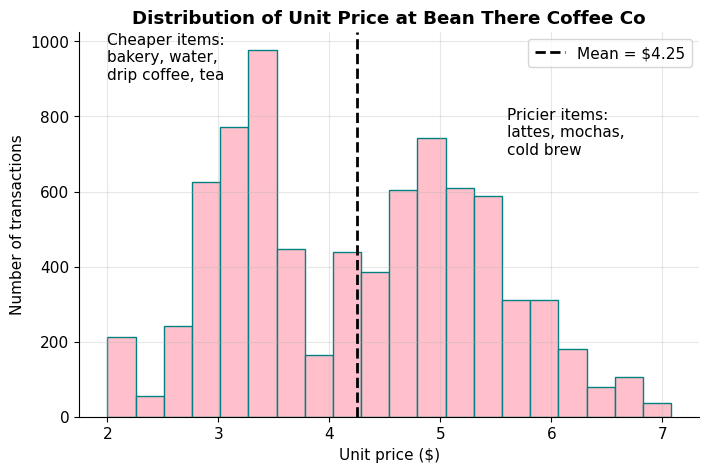

In [6]:
mean_price = sales["unit_price"].mean()

fig, ax = plt.subplots()
ax.hist(sales["unit_price"], bins=20, color="pink", edgecolor="teal")
ax.axvline(mean_price, color="black", ls="--", lw=2, label=f"Mean = \\${mean_price:.2f}")
ax.text(2.0, 900, "Cheaper items:\nbakery, water,\ndrip coffee, tea")
ax.text(5.6, 700, "Pricier items:\nlattes, mochas,\ncold brew")
ax.set_title("Distribution of Unit Price at Bean There Coffee Co")
ax.set_xlabel("Unit price (\\$)")
ax.set_ylabel("Number of transactions")
ax.legend()
plt.show()

#### Explanation: Unit prices range from $2.00 to $7.08, with a mean of about $4.25. The histogram has two humps instead of one bell shape. The first peak is around $3.00 to $3.50 and the second is around $4.75 to $5.50. This is because the menu has two price tiers: bakery items, bottled water, drip coffee, tea, and espresso are mostly $2 to $4.80, while cold brew, cappuccino, chai latte, latte, and mocha are $4.20 to $7.08. Very few items cost over $6.50, which are large sizes of the specialty drinks. The $0 prices were removed first so they don’t distort the shape.

In [7]:
product = ["Cappucino", "Bottled Water", "Drip Coffee", "Latte"]

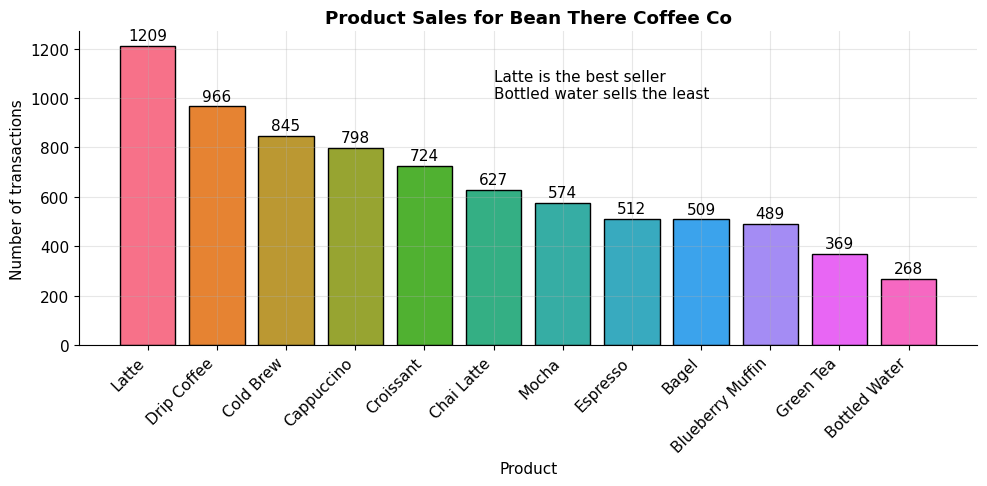

In [22]:
counts = sales["product"].value_counts()

colors = sns.color_palette("husl", len(counts))   # one color for each bar

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor="black")
ax.bar_label(bars, padding=2)
ax.text(5, 1000, "Latte is the best seller\nBottled water sells the least")
ax.set_title("Product Sales for Bean There Coffee Co")
ax.set_xlabel("Product")
ax.set_ylabel("Number of transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Explanation: Latte is the best seller (about 1,209 transactions), followed by drip coffee (about 966) and cold brew (about 845). Bottled water is the least popular (about 268). Most of the top spots go to coffee drinks, so customers come mainly for coffee, with bakery items as a secondary purchase. Sales fall steadily from top to bottom, so a few popular drinks carry the menu.

In [9]:
import matplotlib.pyplot
%matplotlib inline
import seaborn as sns

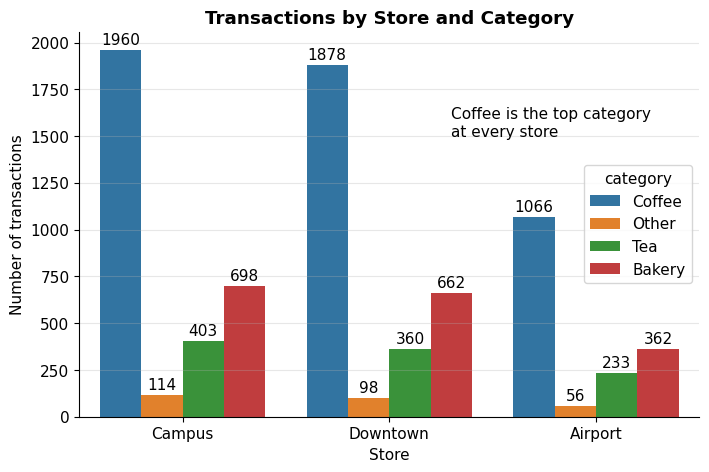

In [10]:
STORES = ["Campus", "Downtown", "Airport"]

fig, ax = plt.subplots()
sns.countplot(x="store", data=sales, hue="category", order=STORES, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=2)
ax.text(1.3, 1500, "Coffee is the top category\nat every store")
ax.set_title("Transactions by Store and Category")
ax.set_xlabel("Store")
ax.set_ylabel("Number of transactions")
sns.despine()
plt.show()

#### Explanation: Campus has the most transactions (3,175), then Downtown (2,998), and the Airport has the fewest (1,717). Within every store the order of categories is the same: with coffee having the greatest number of transactions, then bakery, tea, and "other" having the least. Coffee makes up the majority of sales at each location. Customers buy the same kinds of things everywhere, and the stores differ in how many customers they have.

## 2. Groupby Comparison

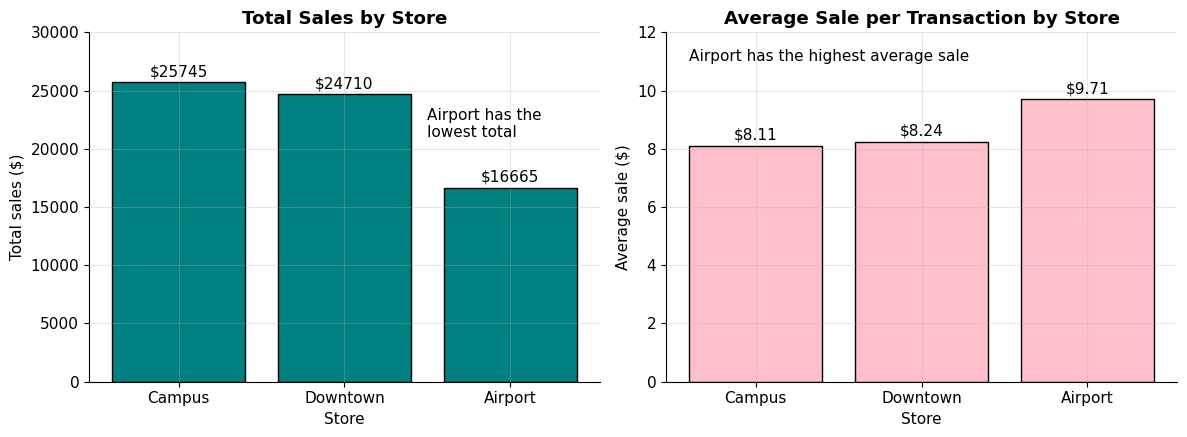

In [11]:
total_rev = sales.groupby("store")["revenue"].sum().reindex(STORES)
avg_rev = sales.groupby("store")["revenue"].mean().reindex(STORES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(total_rev.index, total_rev.values, color="teal", edgecolor="black")
axes[0].bar_label(bars, fmt="\\$%.0f", padding=2)
axes[0].text(1.5, 21000, "Airport has the\nlowest total")
axes[0].set_ylim(0, 30000)
axes[0].set_title("Total Sales by Store")
axes[0].set_xlabel("Store")
axes[0].set_ylabel("Total sales (\\$)")

bars = axes[1].bar(avg_rev.index, avg_rev.values, color="pink", edgecolor="black")
axes[1].bar_label(bars, fmt="\\$%.2f", padding=2)
axes[1].text(-0.4, 11, "Airport has the highest average sale")
axes[1].set_ylim(0, 12)
axes[1].set_title("Average Sale per Transaction by Store")
axes[1].set_xlabel("Store")
axes[1].set_ylabel("Average sale (\\$)")

plt.tight_layout()
plt.show()

#### Explanation: Campus has the highest total sales (about $25,745), closely followed by Downtown (about $24,710). The Airport is far behind at about $16,665, which fits its lower transaction count. Average sale per transaction shows the opposite pattern: the Airport is highest (about $9.71), while Campus ($8.11) and Downtown ($8.24) are almost the same. Airport customers don’t buy more items (about 2 per transaction at every store). The difference comes from price, since the average unit price at the Airport is about $4.92 versus about $4.06 elsewhere. So the Airport earns less overall because it has fewer customers, but each customer is worth more. These totals are before discounts.

# Section 2: Relationship Visualizations

## Scatter Plot

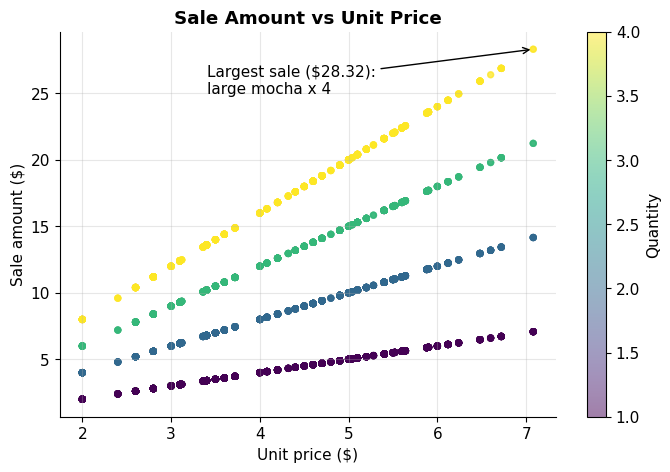

In [12]:
fig, ax = plt.subplots()
sc = ax.scatter(sales["unit_price"], sales["revenue"], c=sales["quantity"],
                cmap="viridis", alpha=0.5, s=18)
fig.colorbar(sc, ax=ax, label="Quantity")
ax.annotate("Largest sale (\\$28.32):\nlarge mocha x 4", xy=(7.08, 28.32), xytext=(3.4, 25),
            arrowprops=dict(arrowstyle="->"))
ax.set_title("Sale Amount vs Unit Price")
ax.set_xlabel("Unit price (\\$)")
ax.set_ylabel("Sale amount (\\$)")
plt.show()

#### Explanation: There is a clear positive trend: higher unit prices lead to bigger sale amounts. The points form four straight bands, one for each quantity (1 to 4), because sale amount is exactly unit price times quantity. Each band rises with price, and a higher quantity lifts the whole band. There are no true outliers. The largest sale ($28.32, a large mocha times 4) is simply the highest price times the highest quantity. The $0 prices and negative quantities were removed during cleaning, since they would have appeared as outliers.

## Corrrelation Heatmap

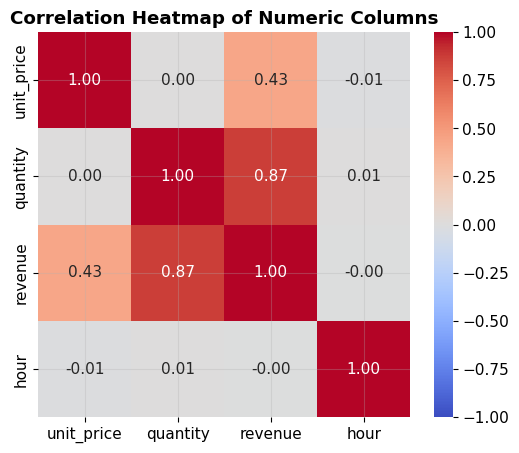

In [13]:
corr = sales[["unit_price", "quantity", "revenue", "hour"]].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Columns")
plt.show()

#### Explanation: The strongest relationship is between quantity and revenue (0.87), then unit price and revenue (0.43). Both make sense because revenue is calculated from them. Quantity matters more because it ranges from 1 to 4, while prices only vary from about $2 to $7. The correlation between unit price and quantity is about 0.00, so customers don’t buy more or fewer items when the item costs more. The hour of the day is also essentially uncorrelated with everything (between -0.01 and 0.01), so time of day doesn’t change what people spend. Since revenue is built from the other columns, the heatmap shows no surprising hidden relationships.

# Summary and Conclusions
* Summary of findings
  * This project looked at 7,890 cleaned purchase records from Bean There Coffee’s three locations (Campus, Downtown, and the Airport) between March and August 2025.
  * Together they total $67,120 in sales before discounts.
  * Prices have two tiers (as seen by the unit price histogram). Bakery, water, drip coffee, and tea make up the cheaper group ($2 to $4.80). Lattes, mochas, cold brew, and other specialty drinks make up the pricier group (up to $7.08). Coffee drinks are about 62% of all sales.
  * Latte is the best selling product. It has the most transactions (about 1,209) and the most revenue (about $13,080). 
  * Campus and Downtown lead on volume of sales, but the Airport leads on the highest average sale amount per customer because the average unit price is higher.
  * Every store sells the same mix. Coffee is the top category at all three locations, so location changes how many customers there are, not what they buy.
  * Sales peak in the morning. Sales are highest around 10 to 11 AM and fall off  throughout the afternoon.
  * Most numeric columns have weak correlation except for a few. Revenue is strongly correlated with quantity (0.87) and moderately to unit price (0.43), which is how it is calculated. Unit price and quantity are unrelated (0.00), so higher prices don’t reduce the number of items bought.

Limitations include that revenue is calculated before any discounts, because the data doesn’t record discount amounts. The data also only covers only six months, so seasonal patterns can’t be judged.

Conclusion: Bean There Coffee is a coffee with business with many morning sales. Specialty drinks, especially lattes, bring in the most money. The Airport serves fewer customers but earns more from each. A possible next step would be to study how discounts affect spending, since that is not measured with this data.